In [ ]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns

# sns.set_style("whitegrid")
# df = pd.read_csv("/content/cleaned_data.csv")
# print(df.shape)


import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
os.makedirs("Charts", exist_ok=True)   # <-- NEW: images yahan save hongi

df = pd.read_csv("/content/cleaned_data.csv")
print(df.shape)

(307507, 85)


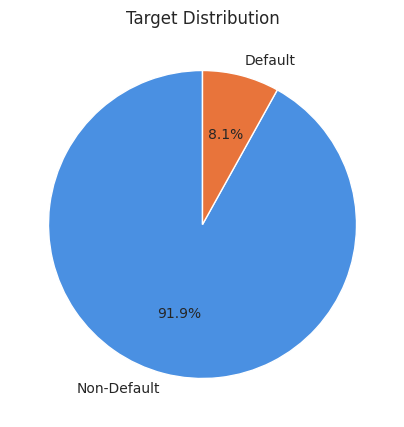

In [ ]:
# counts = df['TARGET'].value_counts()
# plt.figure(figsize=(5,5))
# plt.pie(counts, labels=['Non-Default', 'Default'], autopct='%1.1f%%',
#         colors=['#4A90E2', '#E8743B'], startangle=90)
# plt.title("Target Distribution")
# plt.show()


counts = df['TARGET'].value_counts()
plt.figure(figsize=(5,5))
plt.pie(counts, labels=['Non-Default', 'Default'], autopct='%1.1f%%',
        colors=['#4A90E2', '#E8743B'], startangle=90)
plt.title("Target Distribution")
plt.savefig("target_distribution.png", dpi=150, bbox_inches='tight')   # <-- ye line add ki
plt.show()

In [ ]:
# def default_rate_plot(col, order=None, rotate=0):
#     rate = df.groupby(col)['TARGET'].mean().mul(100)
#     if order is None:
#         rate = rate.sort_values(ascending=False)
#     else:
#         rate = rate.reindex(order)
#     plt.figure(figsize=(9,4))
#     ax = sns.barplot(x=rate.index, y=rate.values, color='#4A90E2')
#     ax.axhline(df['TARGET'].mean()*100, color='red', linestyle='--', label='Overall 8.07%')
#     for i, v in enumerate(rate.values):
#         ax.text(i, v + 0.2, f"{v:.1f}%", ha='center', fontsize=9)
#     plt.title(f"Default Rate by {col}")
#     plt.ylabel("Default Rate (%)")
#     plt.xticks(rotation=rotate)
#     plt.legend()
#     plt.tight_layout()
#     plt.show()



def default_rate_plot(col, order=None, rotate=0):
    rate = df.groupby(col)['TARGET'].mean().mul(100)
    if order is None:
        rate = rate.sort_values(ascending=False)
    else:
        rate = rate.reindex(order)
    plt.figure(figsize=(9,4))
    ax = sns.barplot(x=rate.index, y=rate.values, color='#4A90E2')
    ax.axhline(df['TARGET'].mean()*100, color='red', linestyle='--', label='Overall 8.07%')
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.2, f"{v:.1f}%", ha='center', fontsize=9)
    plt.title(f"Default Rate by {col}")
    plt.ylabel("Default Rate (%)")
    plt.xticks(rotation=rotate, ha='right' if rotate else 'center')
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"Charts/default_rate_{col}.png", dpi=150, bbox_inches='tight')   # <-- NEW
    plt.show()



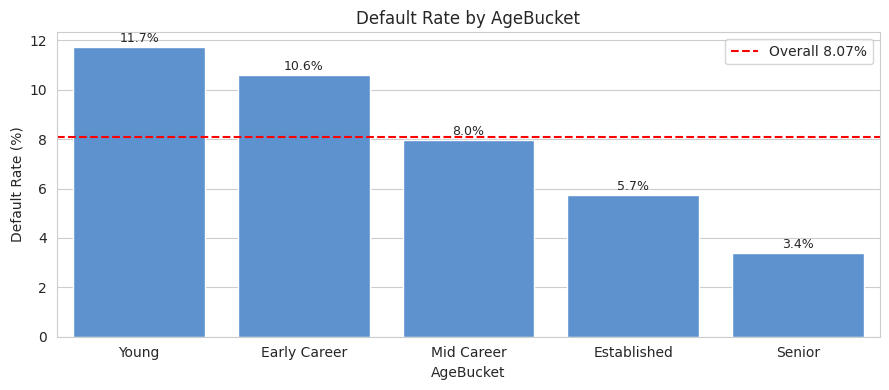

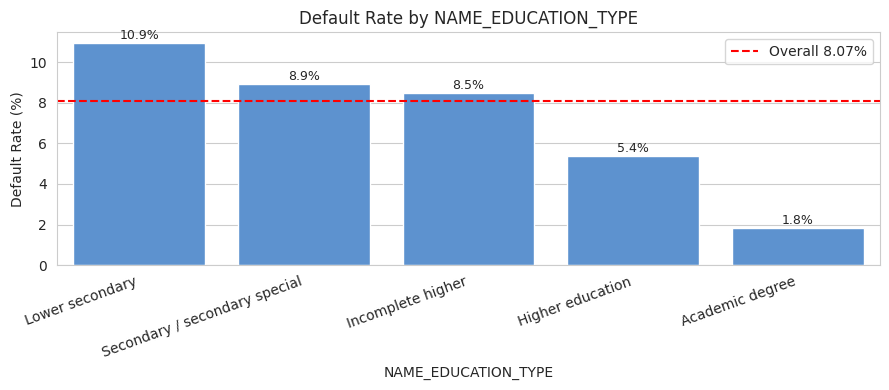

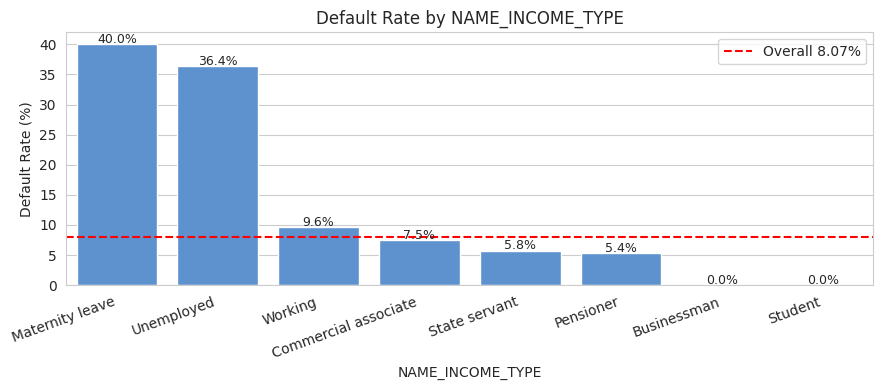

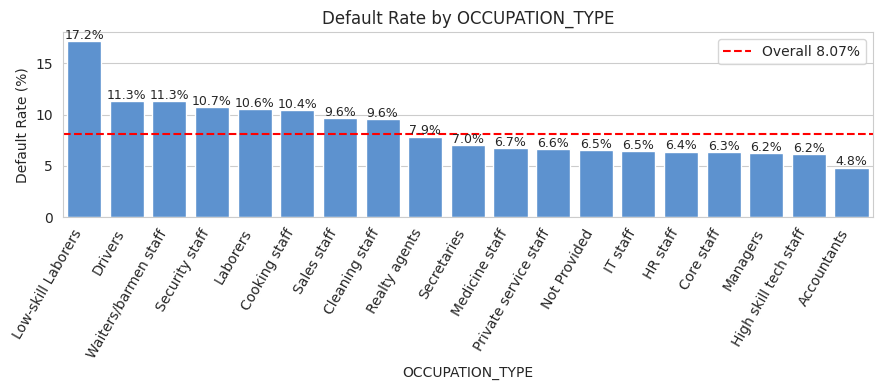

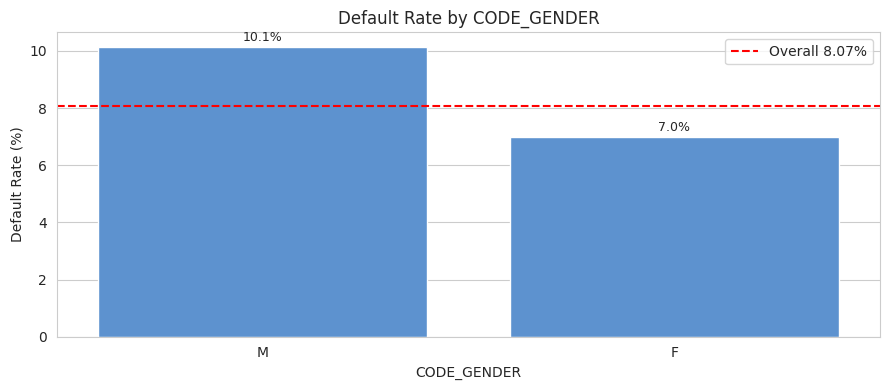

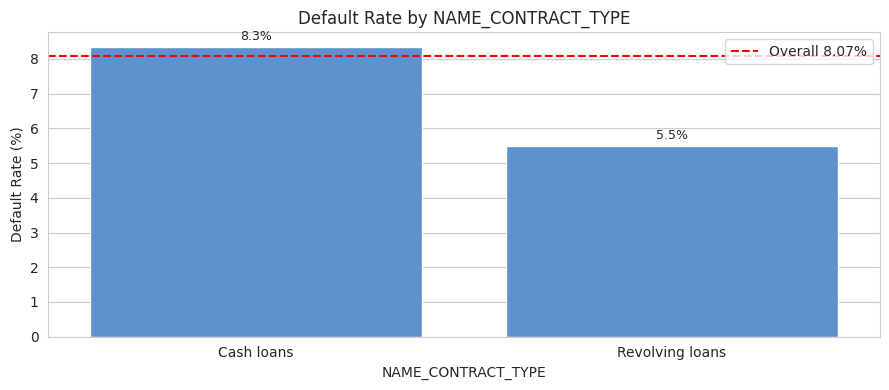

In [ ]:
# default_rate_plot('AgeBucket', order=['Young','Early Career','Mid Career','Established','Senior'])
# default_rate_plot('NAME_EDUCATION_TYPE', rotate=20)
# default_rate_plot('NAME_INCOME_TYPE', rotate=20)
# default_rate_plot('OCCUPATION_TYPE', rotate=60)
# default_rate_plot('CODE_GENDER')
# default_rate_plot('NAME_CONTRACT_TYPE')



default_rate_plot('AgeBucket', order=['Young','Early Career','Mid Career','Established','Senior'])
default_rate_plot('NAME_EDUCATION_TYPE', rotate=20)
default_rate_plot('NAME_INCOME_TYPE', rotate=20)
default_rate_plot('OCCUPATION_TYPE', rotate=60)
default_rate_plot('CODE_GENDER')
default_rate_plot('NAME_CONTRACT_TYPE')



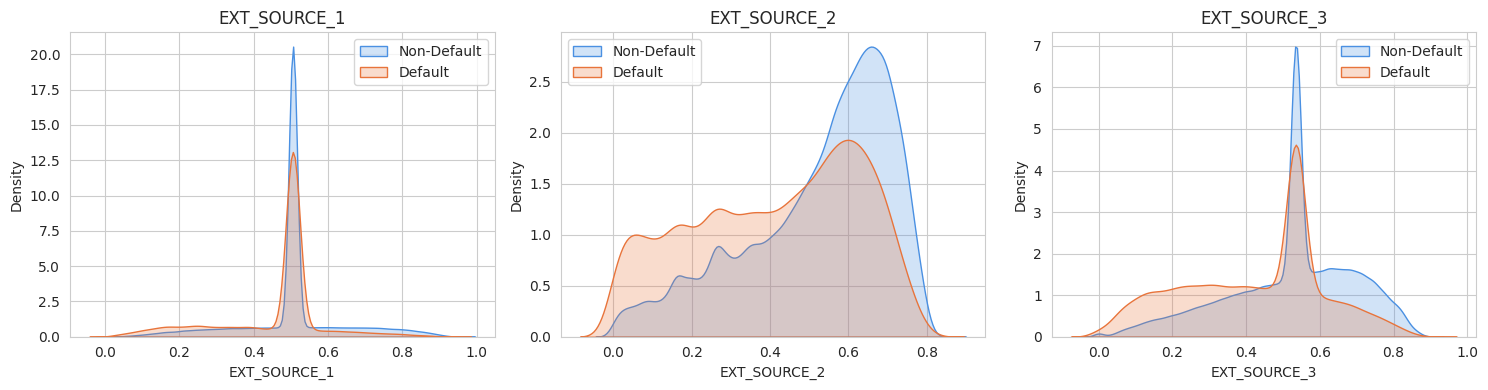

In [ ]:
# fig, axes = plt.subplots(1, 3, figsize=(15,4))
# for ax, c in zip(axes, ['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']):
#     sns.kdeplot(data=df[df.TARGET==0], x=c, ax=ax, label='Non-Default', color='#4A90E2', fill=True)
#     sns.kdeplot(data=df[df.TARGET==1], x=c, ax=ax, label='Default', color='#E8743B', fill=True)
#     ax.set_title(c)
#     ax.legend()
# plt.tight_layout()
# plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, c in zip(axes, ['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']):
    sns.kdeplot(data=df[df.TARGET==0], x=c, ax=ax, label='Non-Default', color='#4A90E2', fill=True)
    sns.kdeplot(data=df[df.TARGET==1], x=c, ax=ax, label='Default', color='#E8743B', fill=True)
    ax.set_title(c)
    ax.legend()
plt.tight_layout()
plt.savefig("Charts/ext_source_kde.png", dpi=150, bbox_inches='tight')   # <-- NEW
plt.show()

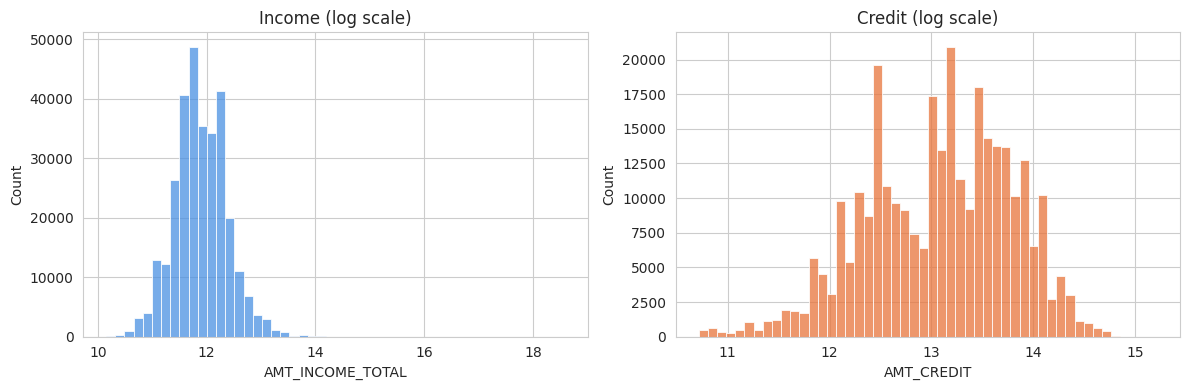

In [ ]:
# fig, axes = plt.subplots(1, 2, figsize=(12,4))
# sns.histplot(np.log1p(df['AMT_INCOME_TOTAL']), bins=50, ax=axes[0], color='#4A90E2')
# axes[0].set_title("Income (log scale)")
# sns.histplot(np.log1p(df['AMT_CREDIT']), bins=50, ax=axes[1], color='#E8743B')
# axes[1].set_title("Credit (log scale)")
# plt.tight_layout()
# plt.show()



fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(np.log1p(df['AMT_INCOME_TOTAL']), bins=50, ax=axes[0], color='#4A90E2')
axes[0].set_title("Income (log scale)")
sns.histplot(np.log1p(df['AMT_CREDIT']), bins=50, ax=axes[1], color='#E8743B')
axes[1].set_title("Credit (log scale)")
plt.tight_layout()
plt.savefig("Charts/income_credit_distribution.png", dpi=150, bbox_inches='tight')   # <-- NEW
plt.show()

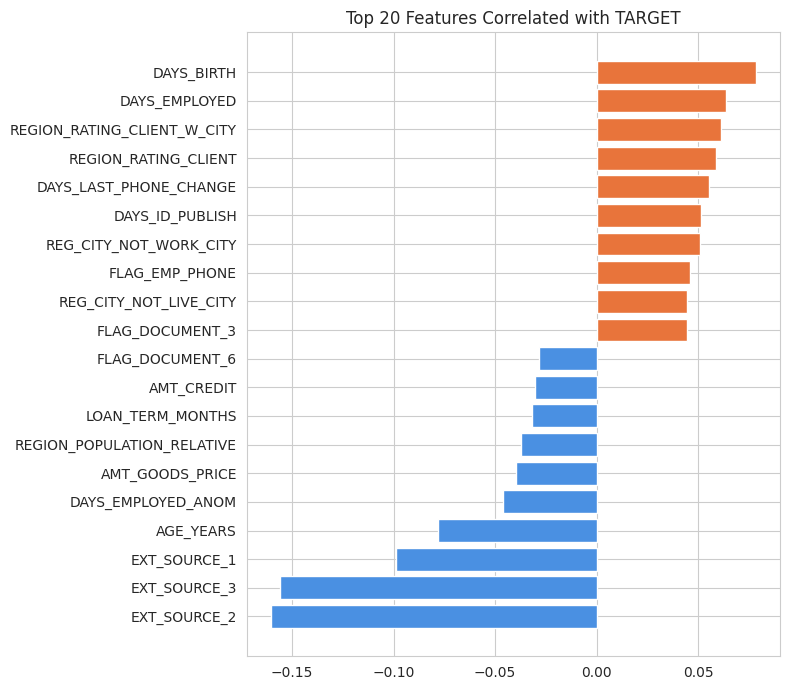

In [ ]:
# corr = df.select_dtypes(include='number').corr()['TARGET'].drop('TARGET')
# top = pd.concat([corr.sort_values().head(10), corr.sort_values().tail(10)])

# plt.figure(figsize=(8,7))
# colors = ['#E8743B' if v > 0 else '#4A90E2' for v in top.values]
# plt.barh(top.index, top.values, color=colors)
# plt.title("Top 20 Features Correlated with TARGET")
# plt.tight_layout()
# plt.show()



corr = df.select_dtypes(include='number').corr()['TARGET'].drop('TARGET')
top = pd.concat([corr.sort_values().head(10), corr.sort_values().tail(10)])

plt.figure(figsize=(8,7))
colors = ['#E8743B' if v > 0 else '#4A90E2' for v in top.values]
plt.barh(top.index, top.values, color=colors)
plt.title("Top 20 Features Correlated with TARGET")
plt.tight_layout()
plt.savefig("Charts/top_correlations.png", dpi=150, bbox_inches='tight')   # <-- NEW
plt.show()


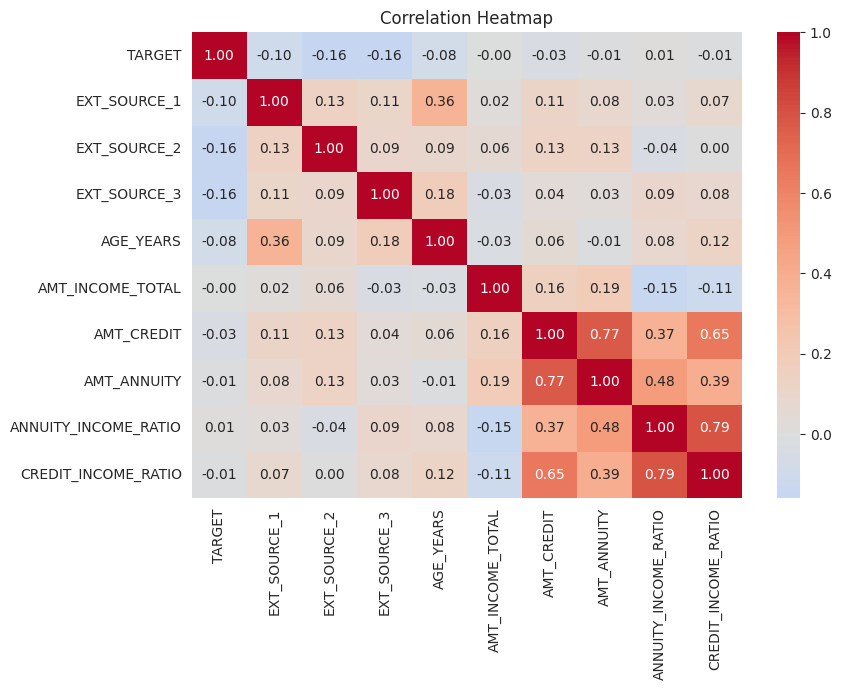

In [ ]:
# cols = ['TARGET','EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3','AGE_YEARS',
#         'AMT_INCOME_TOTAL','AMT_CREDIT','AMT_ANNUITY','ANNUITY_INCOME_RATIO','CREDIT_INCOME_RATIO']
# plt.figure(figsize=(9,7))
# sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
# plt.title("Correlation Heatmap")
# plt.tight_layout()
# plt.show()


cols = ['TARGET','EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3','AGE_YEARS',
        'AMT_INCOME_TOTAL','AMT_CREDIT','AMT_ANNUITY','ANNUITY_INCOME_RATIO','CREDIT_INCOME_RATIO']
plt.figure(figsize=(9,7))
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("Charts/correlation_heatmap.png", dpi=150, bbox_inches='tight')   # <-- NEW
plt.show()


In [ ]:
# from scipy.stats import chi2_contingency, mannwhitneyu

# # Chi-square: categorical vs TARGET
# for col in ['NAME_EDUCATION_TYPE','NAME_INCOME_TYPE','CODE_GENDER','NAME_CONTRACT_TYPE']:
#     p = chi2_contingency(pd.crosstab(df[col], df['TARGET']))[1]
#     print(f"{col}: p-value = {p:.4f} ->", "Significant" if p < 0.05 else "Not significant")

# # Mann-Whitney: numeric default vs non-default
# for col in ['EXT_SOURCE_2','AGE_YEARS','AMT_CREDIT','ANNUITY_INCOME_RATIO']:
#     a = df[df.TARGET==0][col]; b = df[df.TARGET==1][col]
#     p = mannwhitneyu(a, b)[1]
#     print(f"{col}: p-value = {p:.4f} ->", "Significant" if p < 0.05 else "Not significant")



from scipy.stats import chi2_contingency, mannwhitneyu

for col in ['NAME_EDUCATION_TYPE','NAME_INCOME_TYPE','CODE_GENDER','NAME_CONTRACT_TYPE']:
    p = chi2_contingency(pd.crosstab(df[col], df['TARGET']))[1]
    print(f"{col}: p-value = {p:.4f} ->", "Significant" if p < 0.05 else "Not significant")

for col in ['EXT_SOURCE_2','AGE_YEARS','AMT_CREDIT','ANNUITY_INCOME_RATIO']:
    a = df[df.TARGET==0][col]; b = df[df.TARGET==1][col]
    p = mannwhitneyu(a, b)[1]
    print(f"{col}: p-value = {p:.4f} ->", "Significant" if p < 0.05 else "Not significant")



NAME_EDUCATION_TYPE: p-value = 0.0000 -> Significant
NAME_INCOME_TYPE: p-value = 0.0000 -> Significant
CODE_GENDER: p-value = 0.0000 -> Significant
NAME_CONTRACT_TYPE: p-value = 0.0000 -> Significant
EXT_SOURCE_2: p-value = 0.0000 -> Significant
AGE_YEARS: p-value = 0.0000 -> Significant
AMT_CREDIT: p-value = 0.0000 -> Significant
ANNUITY_INCOME_RATIO: p-value = 0.0000 -> Significant


In [ ]:
import zipfile
from google.colab import files

with zipfile.ZipFile("Charts.zip", "w") as z:
    for f in os.listdir("Charts"):
        z.write(os.path.join("Charts", f))

print("Images saved:", os.listdir("Charts"))
files.download("Charts.zip")

Images saved: ['default_rate_CODE_GENDER.png', 'income_credit_distribution.png', 'default_rate_AgeBucket.png', 'default_rate_NAME_EDUCATION_TYPE.png', 'default_rate_NAME_CONTRACT_TYPE.png', 'default_rate_NAME_INCOME_TYPE.png', 'default_rate_OCCUPATION_TYPE.png', 'correlation_heatmap.png', 'ext_source_kde.png', 'top_correlations.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>